<a href="https://colab.research.google.com/github/ivorywang-1005/intro-to-urban-data/blob/main/Scale/S13_Joins_and_Aggregation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Example demo for joining and aggregating data

When you join data together — either as a spatial join (sjoin) or normal join — you can end up with repeated columns. This is because multiple rows in can match to a single row.

In this example, we'll join parks and water fountains. Each park can have many water fountains!

If we want to count how many water fountains we need, we can group or aggregate them.

In [38]:
# Import module and packages
import geopandas as gpd
from pathlib import Path
from shapely import wkt
from google.colab import drive

In [54]:
# You can use the 'Cornell Example Data' folder from the previous class
drive.mount("/content/drive")
DATA_DIRECTORY = "/content/drive/MyDrive/ARCH 6131/example_data"
!ls "{DATA_DIRECTORY}"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
'Borough Boundaries.geojson'
 brooklyn_city_vacant_lots.geojson
 buildings.geojson
 example.3dm
 gridded_tax_lots.3dm
 gridded_tax_lots.csv
 IMG_4106.HEIC
 IMG_4108.HEIC
 NYC_Parks_Drinking_Fountains_20261026.geojson
'Parks_Properties_20261026 (Central Park + Prospect Park).geojson'
 screenshot.png
 test_tree_animation
 trees.3dm
 trees.csv
 trees.geojson


## Load the data

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

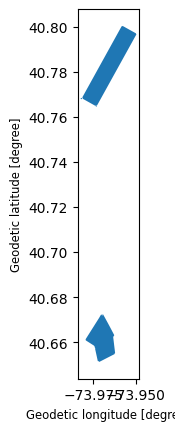

In [55]:
# Load parks
parks_gdf = gpd.read_file(
    Path(DATA_DIRECTORY) / "Parks_Properties_20261026 (Central Park + Prospect Park).geojson")
parks_gdf.plot()

In [56]:
parks_gdf.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 37 columns):
 #   Column           Non-Null Count  Dtype              
---  ------           --------------  -----              
 0   acquisitiondate  2 non-null      datetime64[ms]     
 1   acres            2 non-null      object             
 2   address          2 non-null      object             
 3   borough          2 non-null      object             
 4   class            2 non-null      object             
 5   communityboard   2 non-null      object             
 6   councildistrict  2 non-null      object             
 7   department       2 non-null      object             
 8   gisobjid         2 non-null      object             
 9   gispropnum       2 non-null      object             
 10  globalid         2 non-null      object             
 11  jurisdiction     2 non-null      object             
 12  location         2 non-null      object             
 13  mapped          

In [66]:
# Load water fountains — notice how this one does not have a 'geometry' column
# It will load as a DataFrame, with a 'Point' column
# We need to convert it to a proper GeoDataFrame
fountains_gdf = gpd.read_file(
    Path(DATA_DIRECTORY) / "NYC_Parks_Drinking_Fountains_20261026.geojson"
)

print(f"fountains_gdf is a {type(fountains_gdf).__name__}!")
fountains_gdf.head()

fountains_gdf is a GeoDataFrame!


,:id,geometry
0,row-sa6f_bge5.ecia,POINT (-73.96548 40.7756)
1,row-968j.djhn~ymun,POINT (-73.95146 40.79706)
2,row-ifkq-h55c.cm2m,POINT (-73.96511 40.77756)
3,row-gw3w-zm4e-4ih2,POINT (-73.96871 40.77943)
4,row-hdz7_hjp4.phr3,POINT (-73.96397 40.77763)


In [67]:
fountains_gdf.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 264 entries, 0 to 263
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   :id       264 non-null    object  
 1   geometry  264 non-null    geometry
dtypes: geometry(1), object(1)
memory usage: 4.3+ KB


## Join the data

In [68]:
# To illustrate the point, let's see how many parks there are
print(f"Parks data has {parks_gdf.shape[0]} rows and {parks_gdf.shape[1]} columns")

# ... and how many fountains
print(
    f"Fountains data has {fountains_gdf.shape[0]} rows and {fountains_gdf.shape[1]} columns"
)

Parks data has 2 rows and 37 columns
Fountains data has 264 rows and 2 columns


In [84]:
# Let's do a spatial join — how many results do we have now?
# We should have a lot more rows ... since there are many fountains per park
parks_and_fountains_gdf = parks_gdf.sjoin(fountains_gdf)
print(
    f"Joined data has {parks_and_fountains_gdf.shape[0]} rows and {parks_and_fountains_gdf.shape[1]} columns"
)


Joined data has 251 rows and 39 columns


In [89]:
# Let's do a spatial join — how many results do we have now?
# We should have a lot more rows ... since there are many fountains per park
fountains_and_parks_gdf = fountains_gdf.sjoin(parks_gdf)
print(
    f"Joined data has {parks_and_fountains_gdf.shape[0]} rows and {parks_and_fountains_gdf.shape[1]} columns"
)
# fountains_and_parks_gdf.plot()

Joined data has 251 rows and 39 columns


In [95]:
fountains_and_parks_outer_gdf = fountains_gdf.sjoin(parks_gdf, how='left')
print(
    f"Joined data has {fountains_and_parks_outer_gdf.shape[0]} rows and {fountains_and_parks_outer_gdf.shape[1]} columns"
)
# fountains_and_parks_outer_gdf.plot()

Joined data has 264 rows and 39 columns


## Aggregate the data

In [ ]:
# Let's say we want to sum up the 'FountainCount'
# First we need to convert it from a string to a number
parks_and_fountains_gdf["FountainCount"] = parks_and_fountains_gdf[
    "FountainCount"
].astype(int)

In [ ]:
# Now we can group based on the 'gisobjid' and sum the 'FountainCount'
fountain_count_df = parks_and_fountains_gdf.groupby("gisobjid")[["FountainCount"]].sum()
fountain_count_df

,FountainCount
gisobjid,
100000000,38
100000001,28
100000002,4
100000003,28
100000004,4
...,...
100008344,18
100016513,6
100024490,2


<Axes: >

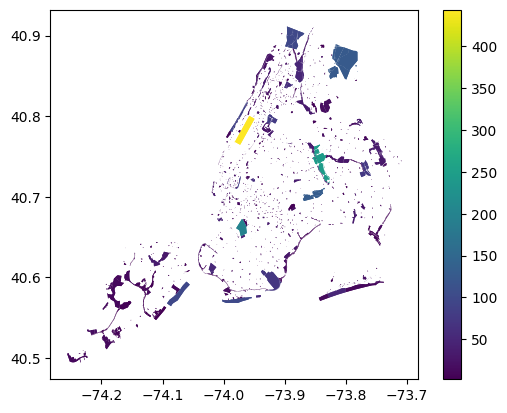

In [ ]:
# ... and now we can join this back to the original parks data!
parks_with_fountain_count_gdf = parks_gdf.set_index("gisobjid").join(fountain_count_df)
parks_with_fountain_count_gdf.plot(column="FountainCount", legend=True)

In [ ]:
# You can define quite a few different ways to aggregate
# In this case, this lets us compare the sum of the 'FountainCount' vs. just counting the geometries
fountain_aggregate_df = parks_and_fountains_gdf.groupby("gisobjid").agg(
    {"FountainCount": "sum", "geometry": "count"}
)
fountain_aggregate_df

,FountainCount,geometry
gisobjid,,
100000000,38,38
100000001,28,28
100000002,4,4
100000003,28,28
100000004,4,4
...,...,...
100008344,18,14
100016513,6,6
100024490,2,2
